# Nastoyka: запуск бара, 60 л и экономика двух вечеров

Автор утвердил десять составов и цены. План: по 60 порций каждого вкуса в пятницу и субботу, порция 50 мл. Это сценарий, а не подтверждённый спрос. Восемь основных по 250 ₽, две премиальные по 300 ₽. Все выходы пока оценочные.

Предыдущие этапы исследования рынка и A/B/C/B2 сохранены [в истории](data/economics/history/README.md); текущий расчёт не импортирует старые дозировки и цены. [Отчёт](docs/economics_report.md) · [Авторское задание](docs/author_specification.md) · [Методика](docs/economics_methodology.md).

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image, Markdown
from scripts import economics as e
ROOT = Path.cwd()
result = e.run()
inputs = e.load_inputs()
out = ROOT / "data/economics/results"
def read(name): return pd.read_csv(out/name)
def fig(name): display(Image(filename=str(ROOT/"figures/economics"/name)))
print("Защищённых первичных файлов:", len(e.check_baseline()["protected_files_sha256"]))
display(pd.Series(result, name="Сценарий 16.10.2026"))

Защищённых первичных файлов: 14


scenario_date                                                                 2026-10-16
selection_source                                                author_selected_menu.csv
recipes_source                                                              recipes.json
yields_source                                                                 yields.csv
prices_source                                                            ingredients.csv
production_source                                                   production_plan.json
optimizer_called                                                                   False
all_initial_yields_estimated                                                        True
total_ready_ml                                                                     60000
total_portions                                                                      1200
purchase_cost_rub                                                               40002.80
used_cost_rub        

## 1. Ассортимент и происхождение данных

Предшествующая база: 368 отзывов и 468 упоминаний, включая неподтверждённые; 198 подтверждённых конкретных упоминаний. Публичные отзывы не равны продажам и не представляют всех гостей. Клюква сохранена прямым решением автора. Новые отзывы не собирались.

Текущие источники: ассортимент CSV, recipes.json, yields.csv, ingredients.csv и production_plan.json. Все составы author_supplied, а не прежние адаптации. Цены предоставлены автором; часть имеет только индексные каталожные ориентиры, не подтверждение магазина СПб.

In [2]:
display(pd.DataFrame(inputs[0]))
display(pd.DataFrame(inputs[2].values()))
display(pd.DataFrame(inputs[3].values())[["ingredient_id","name","supplier","pack_price_rub","pack_size_base","base_unit","price_source_type","confirmation_status","reference_url"]])

,candidate_id,normalized_flavor,tier,price_50ml_rub,selection_status
0,C01,Хреновуха,basic,250,author_selected_preliminary
1,C02,Вишня,basic,250,author_selected_preliminary
2,C03,Малина,basic,250,author_selected_preliminary
3,C04,Лимончелло,basic,250,author_selected_preliminary
4,C05,Щавель,basic,250,author_selected_preliminary
5,C09,Яблоко — базилик,basic,250,author_selected_preliminary
6,C13,Облепиха,basic,250,author_selected_preliminary
7,C14,Клюква,basic,250,author_selected_preliminary
8,C06,Халва,premium,300,author_selected_preliminary
9,C12,Малина — сливки,premium,300,author_selected_preliminary


,candidate_id,yield_ml,yield_status,source_ref,measurement_note
0,C01,470,estimated,docs/author_specification.md,
1,C02,690,estimated,docs/author_specification.md,
2,C03,680,estimated,docs/author_specification.md,
3,C04,1500,estimated,docs/author_specification.md,
4,C05,530,estimated,docs/author_specification.md,
5,C06,450,estimated,docs/author_specification.md,
6,C09,650,estimated,docs/author_specification.md,
7,C12,700,estimated,docs/author_specification.md,
8,C13,720,estimated,docs/author_specification.md,
9,C14,670,estimated,docs/author_specification.md,


,ingredient_id,name,supplier,pack_price_rub,pack_size_base,base_unit,price_source_type,confirmation_status,reference_url
0,vodka,Водка Царская Оригинальная 40%,Ладога,380,1000,ml,author_direct_quote,author_scenario_only,
1,cherry,Вишня замороженная без косточек,METRO,799,1000,g,author_catalog_scenario,catalog_index_reference_not_live_store_confirm...,https://online.metro-cc.ru/products/metro-chef...
2,raspberry,Малина замороженная,METRO,999,1000,g,author_catalog_scenario,catalog_index_reference_not_live_store_confirm...,https://online.metro-cc.ru/products/metro-chef...
3,sea_buckthorn,Облепиха замороженная,METRO,399,1000,g,author_catalog_scenario,catalog_index_reference_not_live_store_confirm...,https://online.metro-cc.ru/products/oblepiha-1kg
4,cranberry,Клюква замороженная,METRO,519,1000,g,author_catalog_scenario,catalog_index_reference_not_live_store_confirm...,https://online.metro-cc.ru/products/klyukva-sa...
5,lemon,Лимоны целые,METRO,179,1000,g,author_catalog_scenario,author_scenario_only,
6,sorrel,Щавель свежий,METRO,139,100,g,author_catalog_scenario,author_scenario_only,
7,basil,Базилик зелёный свежий,METRO,149,50,g,author_catalog_scenario,author_scenario_only,
8,sugar,Сахар,METRO,72.90,1000,g,author_catalog_scenario,author_scenario_only,
9,honey,Мёд,METRO,329,1000,g,author_catalog_scenario,author_scenario_only,


## 2. Производственный план и технологии

Каждому вкусу нужно 6000 мл. Коэффициент 6000 / выход исходной партии не округляется; исходные рецепты не округляются до целых партий. Выход уже включает фильтрацию. 40% — крепость водки, не готовой настойки. Технологии ниже воспроизводят данные автора; отсутствующие длительности операций не придуманы.

In [3]:
for row in inputs[0]:
    cid = row["candidate_id"]
    recipe = inputs[1][cid]
    display(Markdown("**" + cid + " — " + row["normalized_flavor"] + "**"))
    display(pd.DataFrame([{"ingredient_id": key, "quantity": value, "unit": inputs[3][key]["base_unit"]} for key,value in recipe["ingredients"].items()]))
    display(Markdown("\n".join(str(i+1)+". "+s for i,s in enumerate(recipe["technology"]))))
print("C12: наблюдение автора 14 дней; подтверждённый безопасный срок хранения не установлен.")

**C01 — Хреновуха**

,ingredient_id,quantity,unit
0,vodka,500,ml
1,horseradish,95,g
2,ginger,15,g
3,honey,10,g


1. Авторский технологический ориентир: настаивание 1 дн.
2. Получить процеженный напиток; длительность и отдельные операции фильтрации автором не нормированы.

**C02 — Вишня**

,ingredient_id,quantity,unit
0,vodka,500,ml
1,cherry,250,g
2,sugar,250,g


...

1. Авторский технологический ориентир: настаивание 1 дн.
2. Получить процеженный напиток; длительность и отдельные операции фильтрации автором не нормированы.

**C12 — Малина — сливки**

,ingredient_id,quantity,unit
0,vodka,300,ml
1,raspberry,300,g
2,cream,150,ml
3,milk,150,ml
4,sugar,100,g


1. Соединить малину и водку в стеклянной банке, закрыть и оставить на 7 дней в темноте при комнатной температуре, затем процедить.
2. Сливки 10%, молоко 3.2% и сахар нагревать при помешивании до растворения сахара, не доводя до кипения.
3. Остудить сливочную основу и смешать с процеженной малиновой основой.
4. Поместить в холодильник приблизительно на 2 дня. Перед подачей взболтать при расслоении.

C12: наблюдение автора 14 дней; подтверждённый безопасный срок хранения не установлен.


C04 использует весь сок и жёлтую цедру 1900 г целых лимонов; вода отсутствует. C09 — свежие зелёные яблоки 525 г. C06 имеет консервативный выход 450 мл. C12 — 7 дней малиновой основы, отдельная нагретая без кипения и остуженная молочная основа, затем около двух дней в холодильнике. Наблюдение автора о 14 днях не подтверждает безопасность коммерческого хранения.

## 3. Относительный календарь

Пятница D0, суббота D+1. Максимальный известный цикл 30 дней. Ромбы/звезда обозначают операции с неизвестной длительностью, а не нулевое время. Конкретная дата запуска не назначена.

,candidate_id,flavor,phase,duration_days,duration_status,start_day_relative,end_day_relative,start_date,time_interpretation,ready_by_day_relative,launch_reference
0,C01,Хреновуха,infusion,1.0,author_specified,-1,0,NaN,author_duration,0,Friday D0; Saturday D+1
1,C01,Хреновуха,filtration,NaN,not_specified,0,0,NaN,placement_marker_not_zero_duration,0,Friday D0; Saturday D+1
2,C02,Вишня,infusion,30.0,author_specified,-30,0,NaN,author_duration,0,Friday D0; Saturday D+1
3,C02,Вишня,filtration,NaN,not_specified,0,0,NaN,placement_marker_not_zero_duration,0,Friday D0; Saturday D+1
4,C03,Малина,infusion,30.0,author_specified,-30,0,NaN,author_duration,0,Friday D0; Saturday D+1
5,C03,Малина,filtration,NaN,not_specified,0,0,NaN,placement_marker_not_zero_duration,0,Friday D0; Saturday D+1
6,C04,Лимончелло,infusion,14.0,author_specified,-14,0,NaN,author_duration,0,Friday D0; Saturday D+1
7,C04,Лимончелло,filtration,NaN,not_specified,0,0,NaN,placement_marker_not_zero_duration,0,Friday D0; Saturday D+1
8,C05,Щавель,infusion,16.0,author_specified,-16,0,NaN,author_duration,0,Friday D0; Saturday D+1
9,C05,Щавель,filtration,NaN,not_specified,0,0,NaN,placement_marker_not_zero_duration,0,Friday D0; Saturday D+1


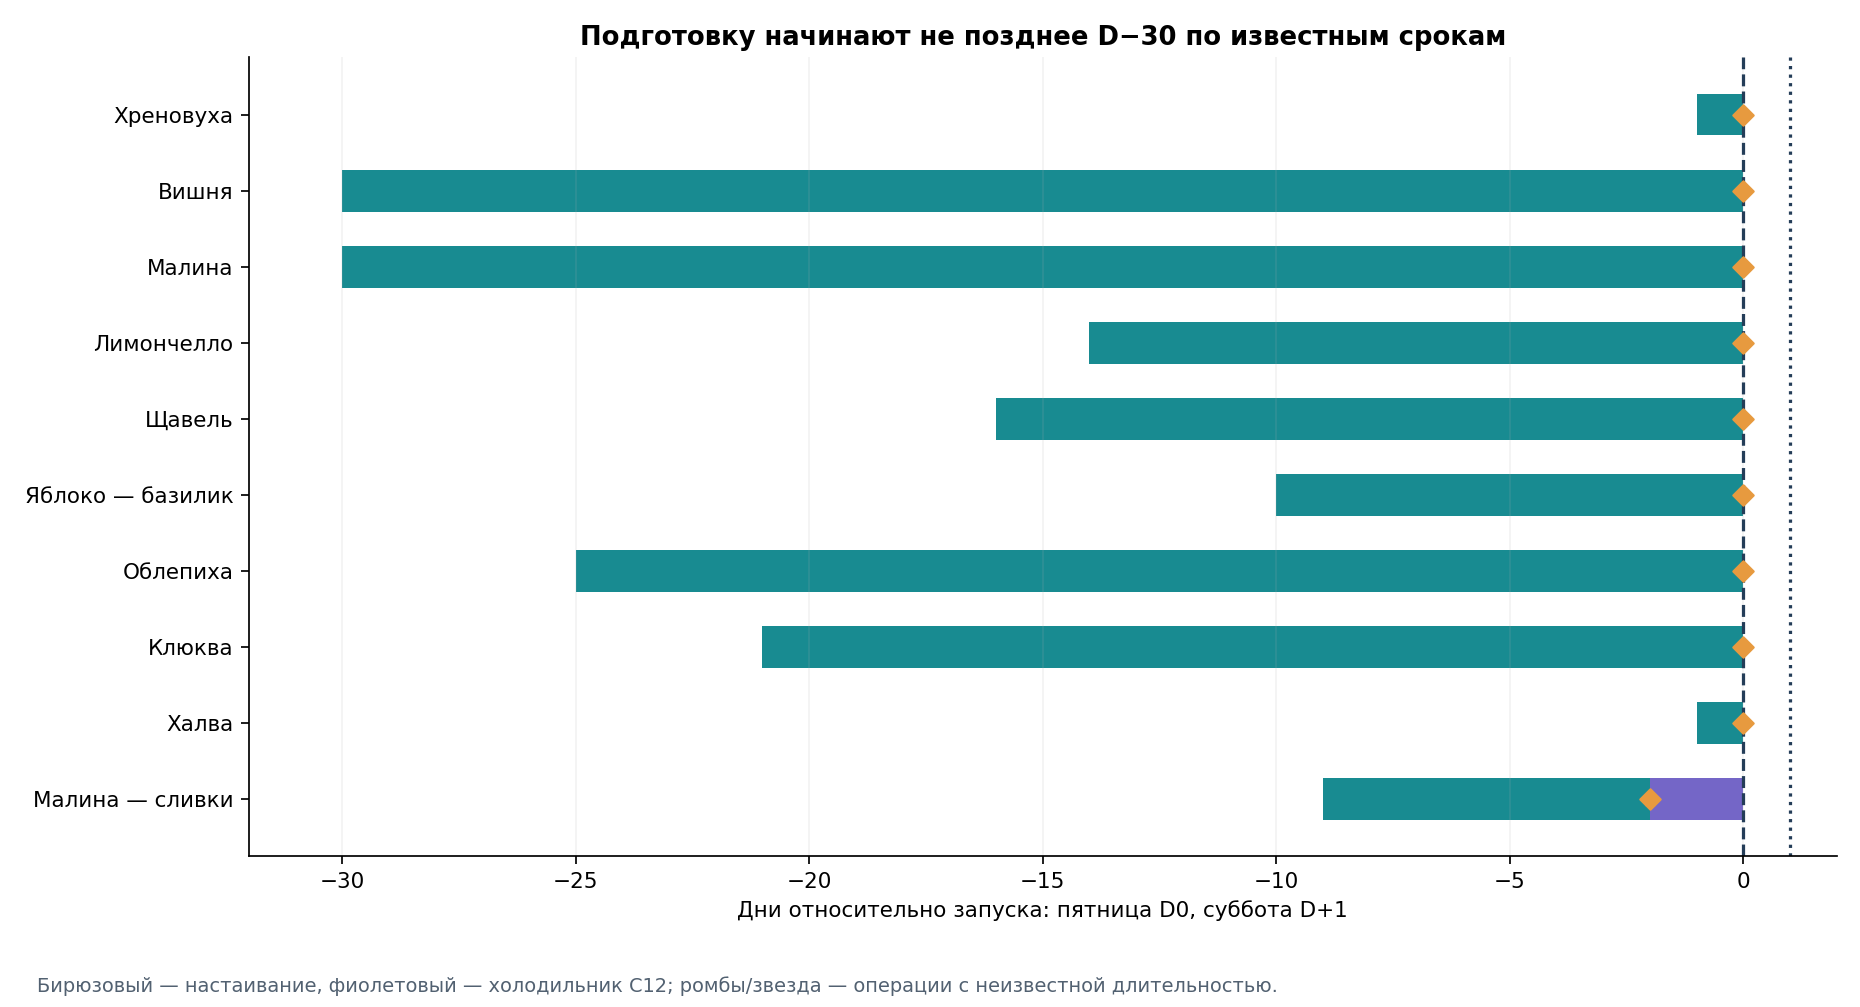

In [4]:
display(read("production_calendar.csv"))
fig("production_calendar.png")

## 4. Закупка целыми упаковками

Потребность общего ингредиента сначала суммируется по десяти вкусам. Только потом применяется округление упаковок вверх. Расход сырья, первый платёж и остаток различаются. Наличие общего компонента не создаёт скидку на тариф; сравнение с раздельными упаковками показывает эффект округления.

,candidate_id,vodka,cherry,raspberry,sea_buckthorn,cranberry,lemon,sorrel,basil,sugar,honey,halva,cream,milk,horseradish,ginger,apple
0,C01,6382.978723,0.000000,0.000000,0.000000,0.000000,0,0.000000,0.000000,0.000000,127.659574,0.0,0.000000,0.000000,1212.765957,191.489362,0.000000
1,C02,4347.826087,2173.913043,0.000000,0.000000,0.000000,0,0.000000,0.000000,2173.913043,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
2,C03,4411.764706,0.000000,2647.058824,0.000000,0.000000,0,0.000000,0.000000,1764.705882,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
3,C04,4000.000000,0.000000,0.000000,0.000000,0.000000,7600,0.000000,0.000000,2000.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
4,C05,5660.377358,0.000000,0.000000,0.000000,0.000000,0,1132.075472,0.000000,0.000000,1132.075472,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
5,C09,4615.384615,0.000000,0.000000,0.000000,0.000000,0,0.000000,138.461538,738.461538,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,4846.153846
6,C13,4166.666667,0.000000,0.000000,4166.666667,0.000000,0,0.000000,0.000000,833.333333,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
7,C14,4477.611940,0.000000,0.000000,0.000000,3582.089552,0,0.000000,0.000000,1343.283582,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
8,C06,6666.666667,0.000000,0.000000,0.000000,0.000000,0,0.000000,0.000000,0.000000,1200.000000,8000.0,0.000000,0.000000,0.000000,0.000000,0.000000
9,C12,2571.428571,0.000000,2571.428571,0.000000,0.000000,0,0.000000,0.000000,857.142857,0.000000,0.0,1285.714286,1285.714286,0.000000,0.000000,0.000000


,ingredient_id,needed_quantity,base_unit,recipes_using,packs_to_buy,purchased_quantity,purchase_cost_rub,used_cost_rub,leftover_quantity,leftover_value_rub,joint_rounding_saving_rub
0,vodka,47300.705335,ml,10,48,48000,18240.0,17974.268027,6.992947e+02,265.731973,1520.0
1,cherry,2173.913043,g,1,3,3000,2397.0,1736.956522,8.260870e+02,660.043478,0.0
2,raspberry,5218.487395,g,2,6,6000,5994.0,5213.268908,7.815126e+02,780.731092,0.0
3,sea_buckthorn,4166.666667,g,1,5,5000,1995.0,1662.500000,8.333333e+02,332.500000,0.0
4,cranberry,3582.089552,g,1,4,4000,2076.0,1859.104478,4.179104e+02,216.895522,0.0
5,lemon,7600.000000,g,1,8,8000,1432.0,1360.400000,4.000000e+02,71.600000,0.0
6,sorrel,1132.075472,g,1,12,1200,1668.0,1573.584906,6.792453e+01,94.415094,0.0
7,basil,138.461538,g,1,3,150,447.0,412.615385,1.153846e+01,34.384615,0.0
8,sugar,9710.840237,g,7,10,10000,729.0,707.920253,2.891598e+02,21.079747,145.8
9,honey,2459.735046,g,3,3,3000,987.0,809.252830,5.402650e+02,177.747170,658.0


,supplier,purchase_cost_rub,used_cost_rub,leftover_value_rub,delivery_cost_rub,minimum_order_rub,terms_status
0,Ладога,18240.0,17974.268027,265.731973,NaN,NaN,not_confirmed_for_author_scenario
1,METRO,19781.8,17193.831852,2587.968148,NaN,NaN,not_confirmed_for_author_scenario
2,Агропарк СПб,1981.0,1189.512275,791.487725,NaN,NaN,not_confirmed_for_author_scenario


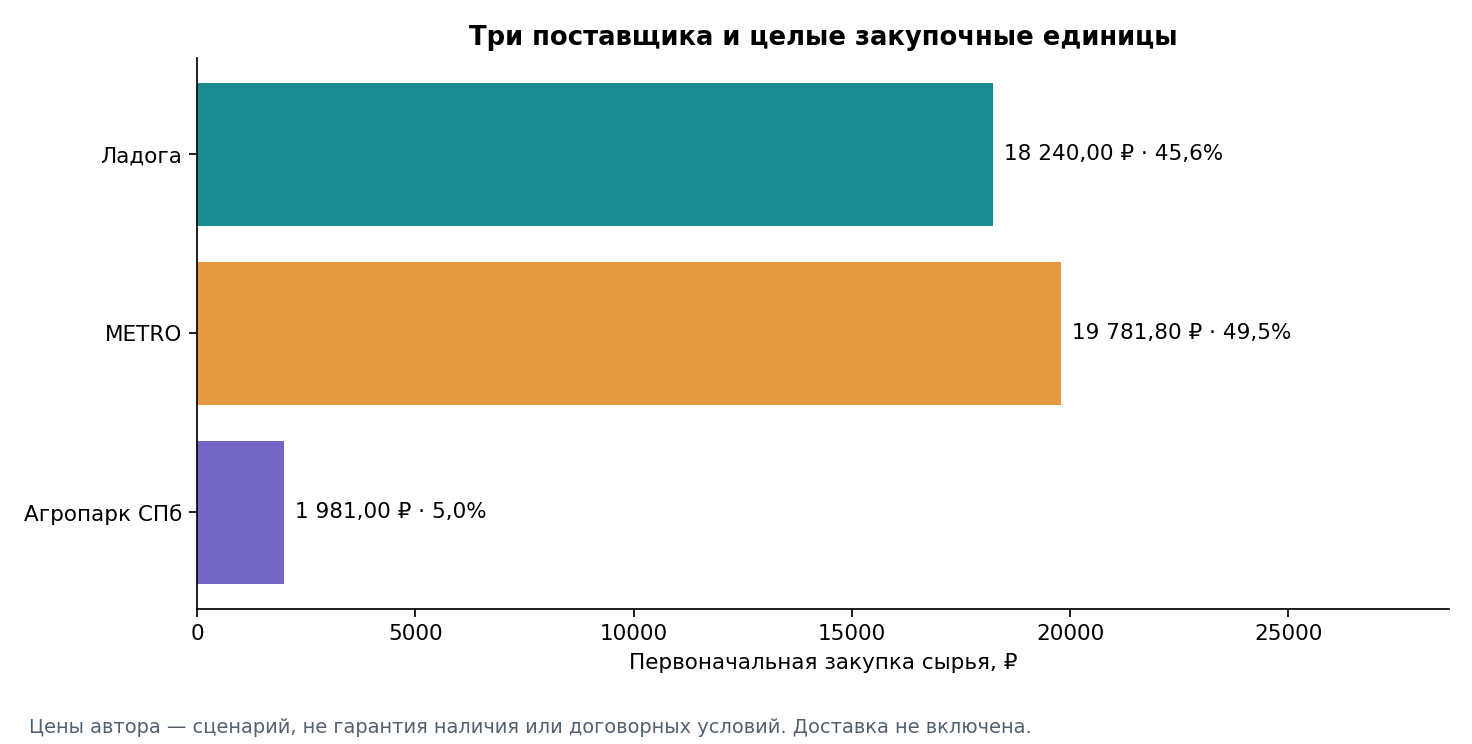

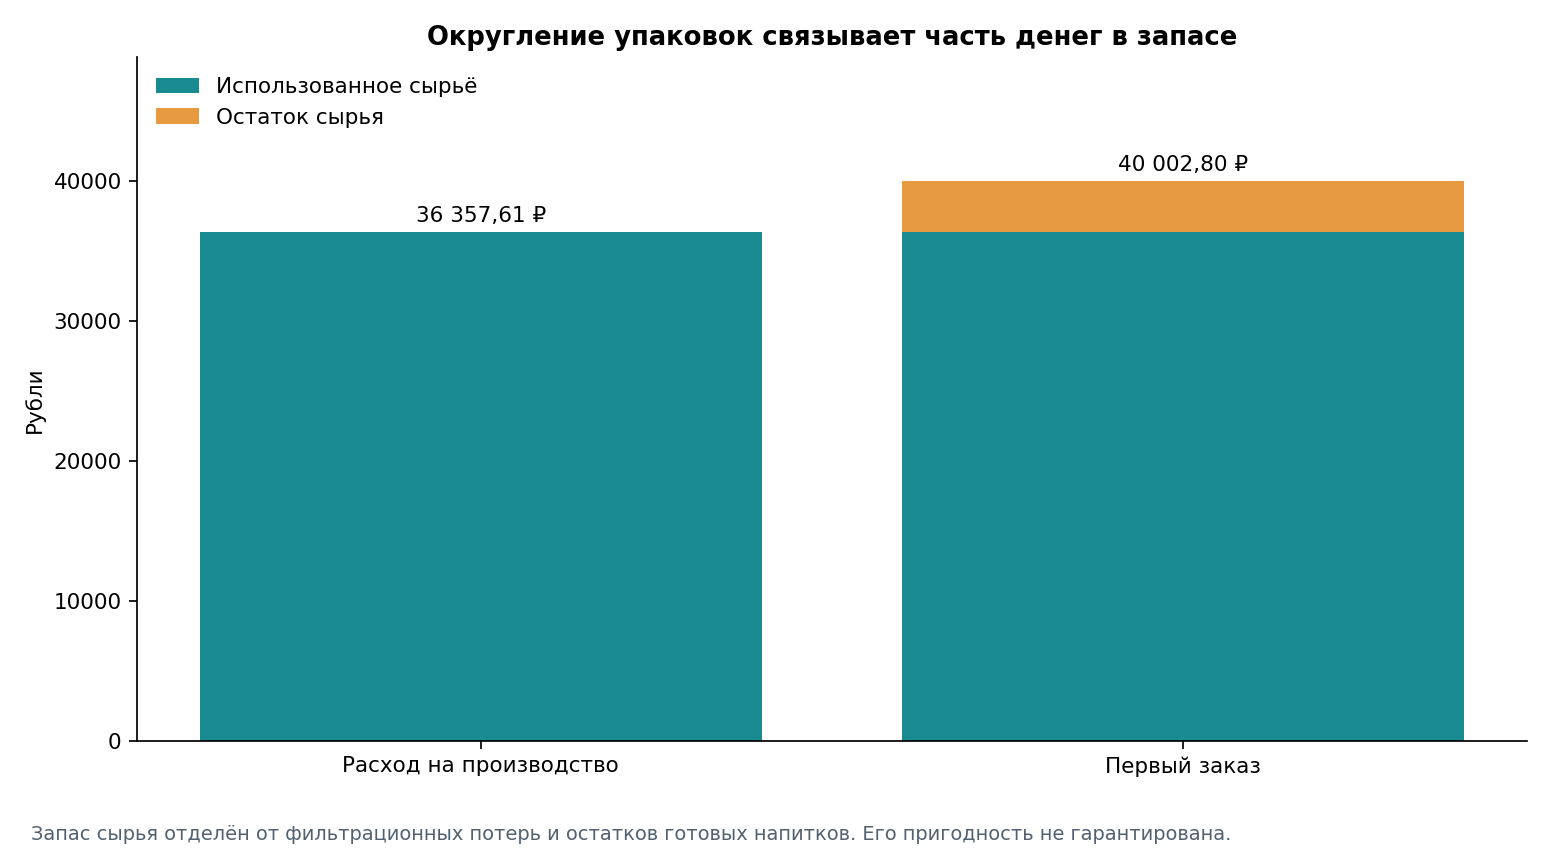

In [5]:
basket = read("procurement.csv")
display(read("ingredient_matrix.csv"))
display(basket[["ingredient_id","needed_quantity","base_unit","recipes_using","packs_to_buy","purchased_quantity","purchase_cost_rub","used_cost_rub","leftover_quantity","leftover_value_rub","joint_rounding_saving_rub"]])
display(read("suppliers.csv"))
fig("supplier_budget.png")
fig("used_vs_purchased.png")

Доставка новых трёх поставщиков и минимумы не установлены; они не равны нулю и не включены в сырьевой бюджет. Авторская ставка водки 380 ₽/л сохранена. Хрен в публичной карточке имеет противоречивый состав с уксусом и солью — нужен именно необработанный корень. Для METRO показаны лишь индексные ориентиры оптовых условий; текущая доступность и выбранный магазин требуют подтверждения.

## 5. Себестоимость и потенциальная выручка

Базовый план 60 л соответствует 1200 порциям. Все суммы вычислены Decimal без промежуточного округления. Материальная маржинальность не включает труд, аренду, налоги, оборудование, доставку и списания, поэтому не является чистой прибылью.

,candidate_id,normalized_flavor,source_batch_cost_rub,planned_yield_ml,scale_factor,used_cost_rub,cost_50ml_rub,price_50ml_rub,material_margin_50ml_rub,material_margin_fraction,potential_revenue_rub,potential_material_contribution_rub
0,C01,Хреновуха,260.275,470,12.765957,3322.659574,27.688830,250,222.311170,0.889245,30000,26677.340426
1,C02,Вишня,407.975,690,8.695652,3547.608696,29.563406,250,220.436594,0.881746,30000,26452.391304
2,C03,Малина,504.280,680,8.823529,4449.529412,37.079412,250,212.920588,0.851682,30000,25550.470588
3,C04,Лимончелло,756.550,1500,4.000000,3026.200000,25.218333,250,224.781667,0.899127,30000,26973.800000
4,C05,Щавель,361.900,530,11.320755,4096.981132,34.141509,250,215.858491,0.863434,30000,25903.018868
5,C09,Яблоко — базилик,276.757,650,9.230769,2554.680000,21.289000,250,228.711000,0.914844,30000,27445.320000
6,C13,Облепиха,396.790,720,8.333333,3306.583333,27.554861,250,222.445139,0.889781,30000,26693.416667
7,C14,Клюква,408.535,670,8.955224,3658.522388,30.487687,250,219.512313,0.878049,30000,26341.477612
8,C06,Халва,332.170,450,13.333333,4428.933333,36.907778,300,263.092222,0.876974,36000,31571.066667
9,C12,Малина — сливки,462.690,700,8.571429,3965.914286,33.049286,300,266.950714,0.889836,36000,32034.085714


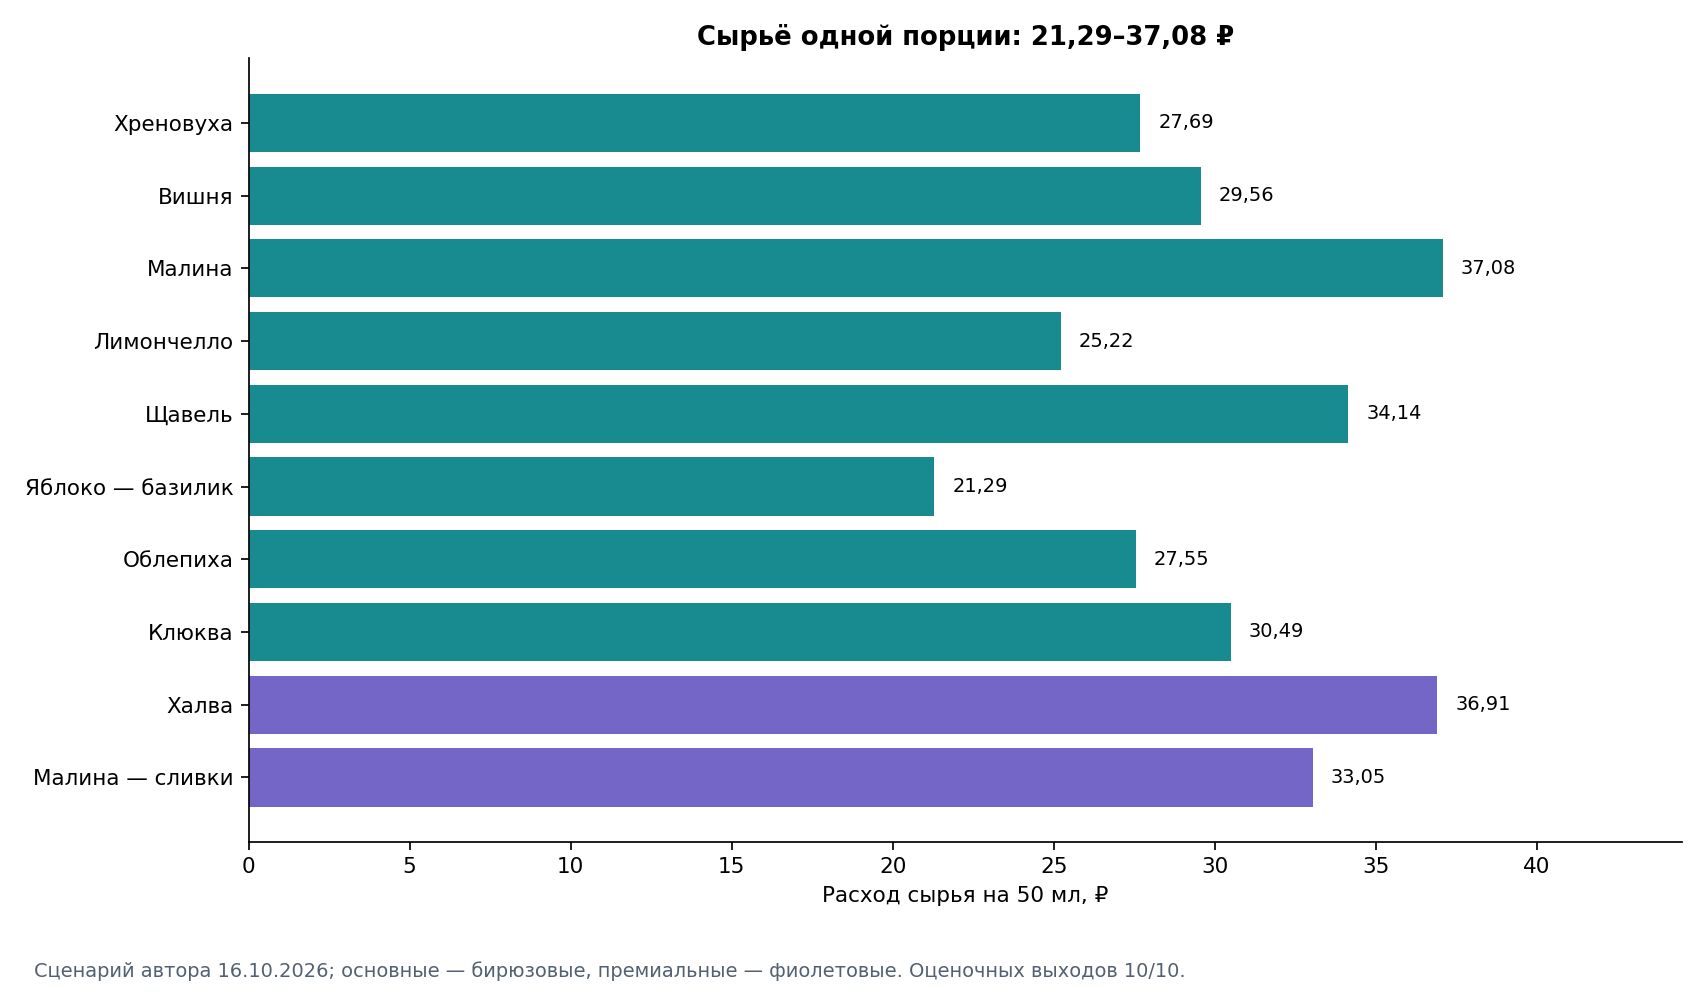

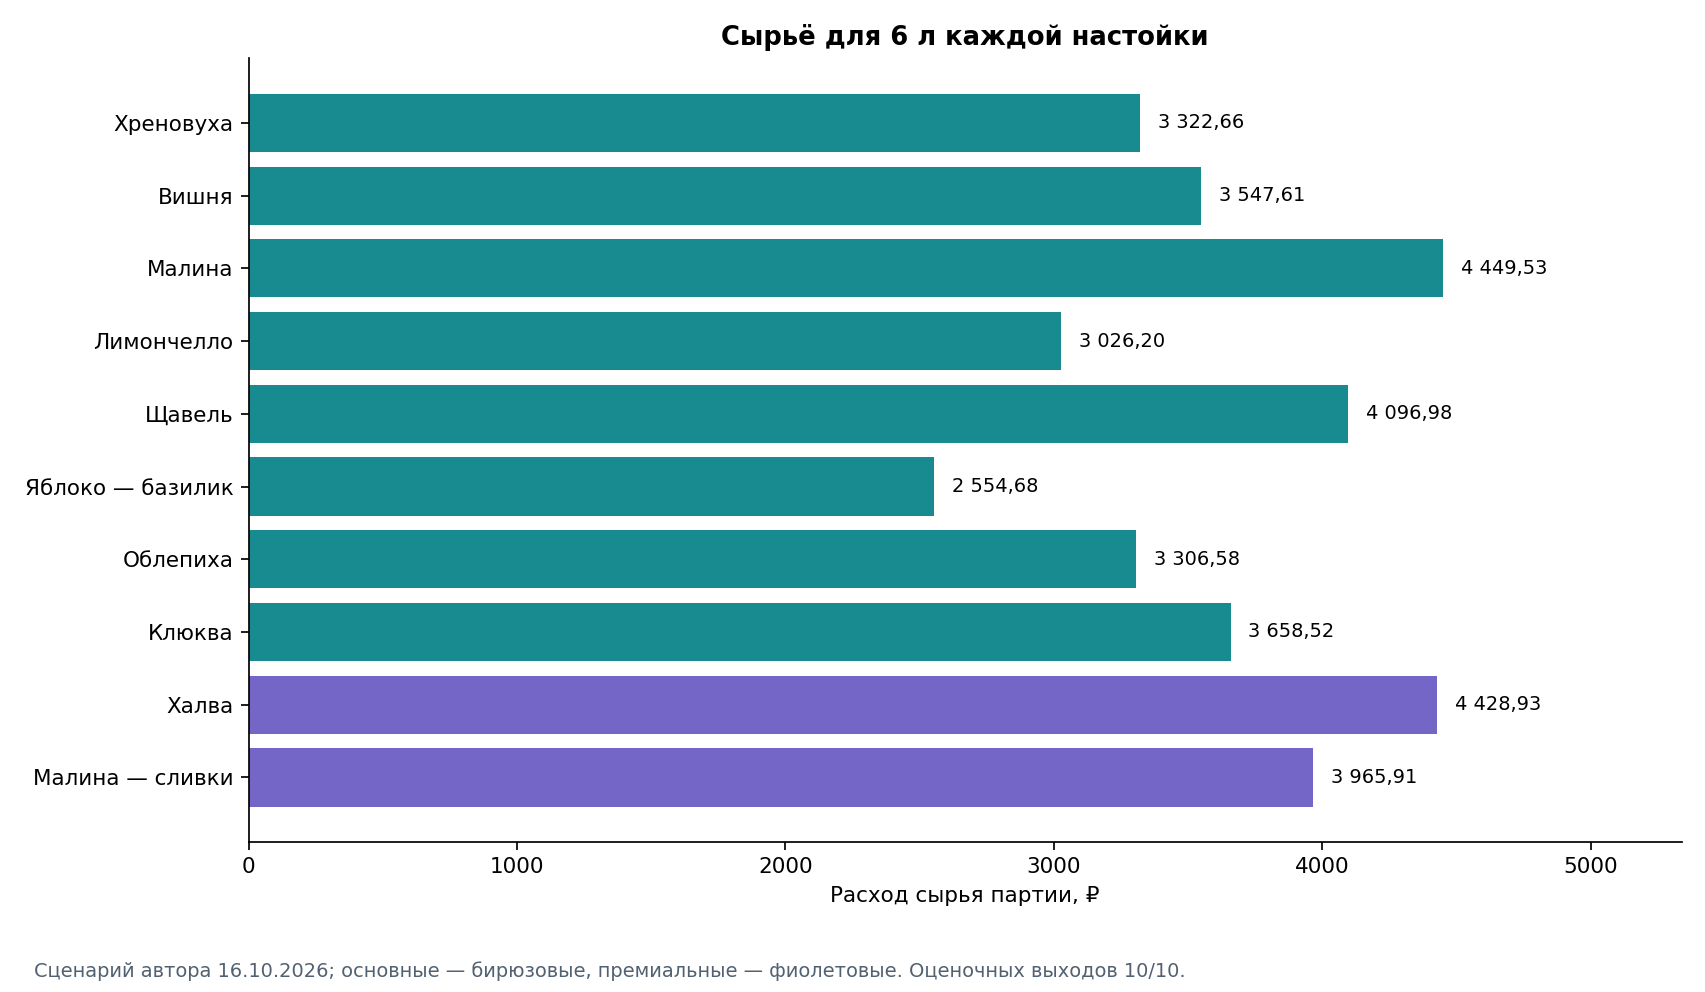

Агрегат до округления: 36357.61
Сумма показанных округлённых строк: 36357.60


In [6]:
costs = read("recipe_costs.csv")
display(costs[["candidate_id","normalized_flavor","source_batch_cost_rub","planned_yield_ml","scale_factor","used_cost_rub","cost_50ml_rub","price_50ml_rub","material_margin_50ml_rub","material_margin_fraction","potential_revenue_rub","potential_material_contribution_rub"]])
fig("cost_50ml.png")
fig("cost_6l.png")
print("Агрегат до округления:", e.money(result["used_cost_rub"]))
print("Сумма показанных округлённых строк:", e.money(result["displayed_item_costs_sum_rub"]))

Контрольный бюджет 40 002,80 ₽ и разбивка по поставщикам сходятся точно. Сумма округлённых строк сырья 36 357,60 ₽; сумма до округления даёт 36 357,61 ₽. Поэтому вклад после сырья 275 642,39 ₽ и остаток 3 645,19 ₽ отличаются от авторских ориентиров на копейку. Формулы не подгонялись.

## 6. Частичная реализация

Во всех сценариях уже произведены все 60 л. Выросшая доля непроданного не уменьшает потраченные ингредиенты. Выручка только от проданных порций; стоимость сырья проданного, всех произведённых порций и остаток готовой продукции разделены.

,sell_through,produced_portions,sold_portions,unsold_portions,unsold_ready_ml,realized_revenue_rub,all_production_material_rub,sold_portions_material_rub,unsold_finished_material_value_rub,contribution_after_sold_material_rub,revenue_minus_all_production_material_rub,cash_after_ingredient_purchase_rub,sales_status
0,0.5,1200,600.0,600.0,30000.0,156000.0,36357.612154,18178.806077,18178.806077,137821.193923,119642.387846,115997.2,assumed_uniform_by_flavor
1,0.7,1200,840.0,360.0,18000.0,218400.0,36357.612154,25450.328508,10907.283646,192949.671492,182042.387846,178397.2,assumed_uniform_by_flavor
2,0.9,1200,1080.0,120.0,6000.0,280800.0,36357.612154,32721.850939,3635.761215,248078.149061,244442.387846,240797.2,assumed_uniform_by_flavor
3,1.0,1200,1200.0,0.0,0.0,312000.0,36357.612154,36357.612154,0.000000,275642.387846,275642.387846,271997.2,assumed_uniform_by_flavor


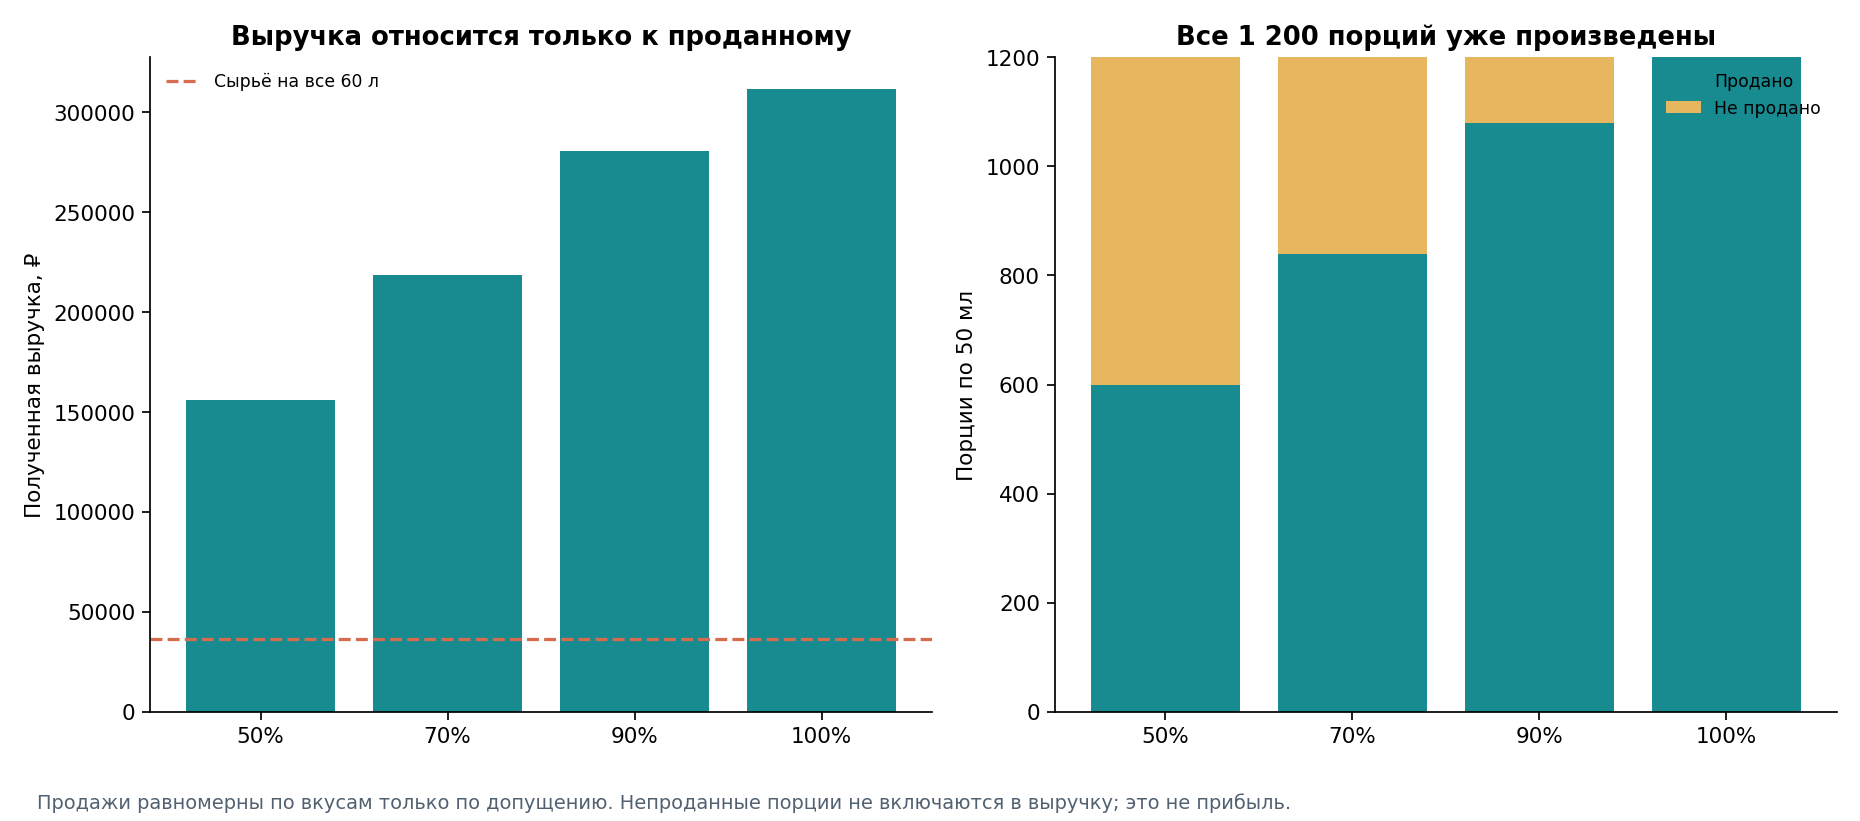

In [7]:
display(read("sales_scenarios.csv"))
fig("sell_through.png")

## 7. Доля премиальных продаж и предел запаса

При 5/20/35% средние цены 252,50/260/267,50 ₽. Доли вкусов внутри уровня равны по допущению. Премиальных порций всего 240, поэтому 35% не совместимы с реализацией всех 1200 порций. Невыполнимые сочетания помечены и не получают выручку от отсутствующих порций.

In [8]:
mix = read("premium_mix.csv")
display(mix)
assert mix.loc[~mix.stock_feasible,"realized_revenue_if_feasible_rub"].isna().all()

,premium_share,requested_total_sell_through,weighted_price_rub,weighted_material_cost_rub,material_margin_fraction,requested_sold_portions,max_feasible_total_portions,stock_feasible,realized_revenue_if_feasible_rub,sales_status
0,0.05,0.5,252.5,29.420412,0.883484,600.0,1010.526316,True,151500.0,scenario_not_observed_equal_within_tier
1,0.05,0.7,252.5,29.420412,0.883484,840.0,1010.526316,True,212100.0,scenario_not_observed_equal_within_tier
2,0.05,0.9,252.5,29.420412,0.883484,1080.0,1010.526316,False,NaN,scenario_not_observed_equal_within_tier
3,0.05,1.0,252.5,29.420412,0.883484,1200.0,1010.526316,False,NaN,scenario_not_observed_equal_within_tier
4,0.20,0.5,260.0,30.298010,0.883469,600.0,1200.000000,True,156000.0,scenario_not_observed_equal_within_tier
5,0.20,0.7,260.0,30.298010,0.883469,840.0,1200.000000,True,218400.0,scenario_not_observed_equal_within_tier
6,0.20,0.9,260.0,30.298010,0.883469,1080.0,1200.000000,True,280800.0,scenario_not_observed_equal_within_tier
7,0.20,1.0,260.0,30.298010,0.883469,1200.0,1200.000000,True,312000.0,scenario_not_observed_equal_within_tier
8,0.35,0.5,267.5,31.175608,0.883456,600.0,685.714286,True,160500.0,scenario_not_observed_equal_within_tier
9,0.35,0.7,267.5,31.175608,0.883456,840.0,685.714286,False,NaN,scenario_not_observed_equal_within_tier


## 8. Цены, выходы и округление упаковок

Изменение цен не является новой договорной котировкой. Изменение выхода сохраняет готовую цель 6000 мл каждого вкуса, пересчитывая расход и упаковки. Если после изменения не проходит индексный порог ставки METRO, это отмечено; другая ставка автоматически не подставляется. Измеренный выход вводится только в yields.csv, без правки кода.

In [9]:
display(read("price_sensitivity.csv").loc[lambda x: x.candidate_id.eq("ALL")])
display(read("yield_sensitivity.csv").loc[lambda x: x.candidate_id.eq("ALL")])
display(basket[["ingredient_id","packs_to_buy","separate_recipe_packs","joint_rounding_saving_rub"]])

,price_change,candidate_id,cost_50ml_rub,used_cost_rub,material_margin_fraction,purchase_cost_rub
10,-0.1,ALL,27.268209,32721.850939,0.895122,36002.52
21,0.0,ALL,30.298010,36357.612154,0.883469,40002.80
32,0.1,ALL,33.327811,39993.373370,0.871816,44003.08
43,0.2,ALL,36.357612,43629.134585,0.860163,48003.36


,yield_multiplier,candidate_id,changed_yield_ml,target_ready_ml,cost_50ml_rub,used_cost_rub,purchase_cost_rub,material_margin_fraction,indexed_rate_thresholds_met,unmet_indexed_threshold_ingredients
10,0.8,ALL,NaN,60000,NaN,45447.015193,48464.7,0.854336,True,NaN
21,0.9,ALL,NaN,60000,NaN,40397.346838,42699.3,0.870521,True,NaN
32,1.0,ALL,NaN,60000,NaN,36357.612154,40002.8,0.883469,True,NaN
43,1.1,ALL,NaN,60000,NaN,33052.374686,35801.1,0.894063,False,cherry


,ingredient_id,packs_to_buy,separate_recipe_packs,joint_rounding_saving_rub
0,vodka,48,52,1520.0
1,cherry,3,3,0.0
2,raspberry,6,6,0.0
3,sea_buckthorn,5,5,0.0
4,cranberry,4,4,0.0
5,lemon,8,8,0.0
6,sorrel,12,12,0.0
7,basil,3,3,0.0
8,sugar,10,12,145.8
9,honey,3,5,658.0


## 9. Что нужно подтвердить

Поставка водки по авторской ставке, акции/торговый центр METRO, свежий необработанный хрен, единицы заказа Агропарка, доставка и минимумы остаются предметом согласования. Нужны надлежащие условия хранения молочного варианта и проверка требований пищевой безопасности. Измеренные выходы следует внести после производства. Новые рецептурные эксперименты в этот этап не включены.

60 порций каждого вкуса за вечер — план автора, а не доказанный спрос. Упаковочные остатки и непроданные напитки — разные риски. Высокая сырьевая маржинальность не устанавливает полную прибыльность бара. Состав сохранён; PR остаётся Draft, main не изменяется без отдельного разрешения.

In [10]:
assert e.check_baseline()
manifest = json.loads((out/"run_manifest.json").read_text())
for name,digest in manifest["inputs_sha256"].items():
    assert hashlib.sha256((ROOT/"data/economics"/name).read_bytes()).hexdigest() == digest
assert result["total_ready_ml"] == 60000 and result["total_portions"] == 1200
assert e.money(result["purchase_cost_rub"]) == e.money(sum(e.D(str(x)) for x in read("procurement.csv").purchase_cost_rub))
assert not result["optimizer_called"]
print("Текущая модель, 60 л, 1200 порций и защищённая база проверены. Тесты запускаются отдельно свежим pytest.")

Текущая модель, 60 л, 1200 порций и защищённая база проверены. Тесты запускаются отдельно свежим pytest.
